# Chapitre 7 - Cours 2 : optimisme, Cp, AIC, BIC, nombre effectif de paramètres et dimension VC

Le notebook précédent a montré que l'erreur d'apprentissage $\overline{\mathrm{err}}$ est
trop optimiste. Nous quantifions ici cet **optimisme** (sections 7.4 à 7.9 du livre) et en
déduisons des critères analytiques de sélection de modèle :

1. erreur intra-échantillon, optimisme et formule $\omega = \frac2N\sum\mathrm{Cov}(\hat y_i, y_i)$ ;
2. les critères **Cp** et **AIC**, illustrés sur les données de phonèmes (figure 7.4) ;
3. le **nombre effectif de paramètres** $\mathrm{df}(\mathbf S) = \mathrm{trace}(\mathbf S)$ ;
4. le critère **BIC** et son interprétation bayésienne, comparé à AIC ;
5. la **dimension de Vapnik-Chervonenkis** (figures 7.5 et 7.6).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch07_selection as sel
set_style()

## 1. Erreur intra-échantillon et optimisme

Dans cette section, les entrées $x_1, \dots, x_N$ sont **fixées** et seules les réponses
sont aléatoires. On imagine de **nouvelles** réponses $Y_i^0$ observées aux mêmes points
$x_i$, indépendantes des $y_i$ mais de même loi. L'**erreur intra-échantillon**
(éq. (7.18) du livre) est

$$
\mathrm{Err}_{\mathrm{in}} = \frac1N \sum_{i=1}^N \mathbb E_{Y^0}\big[L(Y_i^0, \hat f(x_i)) \,\big|\, \mathcal T\big].
$$

Elle diffère de $\mathrm{Err}_{\mathcal T}$ uniquement par le lieu des points test : on
évalue aux points d'apprentissage au lieu de points $X^0$ nouveaux.

On définit l'**optimisme** comme l'écart $\mathrm{op} = \mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}}$
(éq. (7.19)), et l'**optimisme moyen** $\omega = \mathbb E_{\mathbf y}(\mathrm{op})$ (éq. (7.20)),
où l'espérance porte sur les réponses d'apprentissage. Pour la perte quadratique (et
d'autres pertes), on a le résultat fondamental (éq. (7.21), démontré dans l'exercice 7.4) :

$$\omega = \frac2N \sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i).$$

Autrement dit,
$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \mathbb E_{\mathbf y}(\overline{\mathrm{err}}) + \frac2N\sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i). \tag{7.22}$$

> **Intuition.** Plus une observation $y_i$ influence sa propre prédiction $\hat y_i$,
> plus l'erreur d'apprentissage est flatteuse. Un modèle qui interpole ($\hat y_i = y_i$)
> a une covariance maximale $\mathrm{Var}(y_i) = \sigma^2_\varepsilon$ et une erreur
> d'apprentissage nulle.

**Cas linéaire.** Si $\hat{\mathbf y} = \mathbf H\mathbf y$ est un ajustement par
moindres carrés sur $d$ variables (ou fonctions de base) et $Y = f(X) + \varepsilon$ avec
$\mathrm{Var}(\varepsilon) = \sigma_\varepsilon^2$, alors
$\mathrm{Cov}(\hat{\mathbf y}, \mathbf y) = \mathbf H\,\mathrm{Var}(\mathbf y) = \sigma^2_\varepsilon\mathbf H$,
donc $\sum_i \mathrm{Cov}(\hat y_i, y_i) = \sigma^2_\varepsilon\,\mathrm{trace}(\mathbf H) = d\,\sigma^2_\varepsilon$
(éq. (7.23)), et

$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \mathbb E_{\mathbf y}(\overline{\mathrm{err}}) + 2\,\frac dN\,\sigma^2_\varepsilon. \tag{7.24}$$

L'optimisme croît **linéairement** avec $d$ et décroît comme $1/N$.

Vérifions (7.24) par simulation : $N = 40$ entrées fixées, $f(x) = \sin(2\pi x_1) + x_2$,
régression polynomiale en $x_1$ de degré variable (avec $x_2$), $\sigma_\varepsilon = 1$.
On estime $\mathbb E(\mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}})$ en tirant
beaucoup de vecteurs $\mathbf y$ et, pour chacun, des réponses neuves $\mathbf Y^0$.

In [2]:
rng = np.random.RandomState(0)
N, sig, n_rep = 40, 1.0, 4000
X = rng.rand(N, 2)
fx = np.sin(2 * np.pi * X[:, 0]) + X[:, 1]
degrees = np.arange(1, 11)
opt_mc, d_list = [], []
for deg in degrees:
    B = np.column_stack([X[:, 0] ** j for j in range(1, deg + 1)] + [X[:, 1]])
    H = sel.hat_matrix(B)
    d_list.append(np.trace(H))
    Y = fx + sig * rng.randn(n_rep, N)
    Y0 = fx + sig * rng.randn(n_rep, N)
    Yhat = Y @ H.T
    err = ((Y - Yhat) ** 2).mean(1)
    err_in = ((Y0 - Yhat) ** 2).mean(1)
    opt_mc.append((err_in - err).mean())
d_list = np.array(d_list)

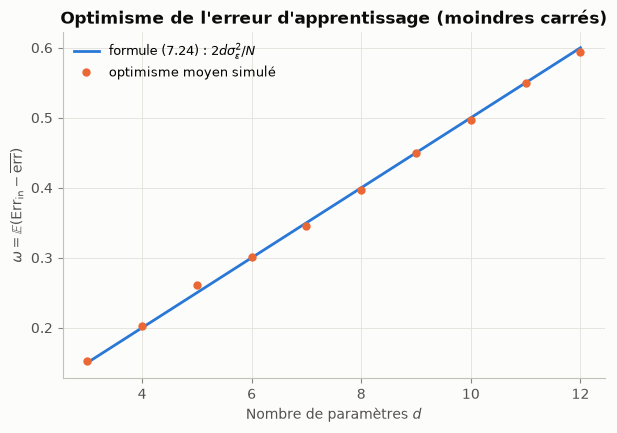

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(d_list, 2 * d_list * sig ** 2 / N, color=BLUE, label=r"formule (7.24) : $2d\sigma_\varepsilon^2/N$")
ax.plot(d_list, opt_mc, "o", color=ORANGE, label="optimisme moyen simulé")
ax.set_xlabel("Nombre de paramètres $d$")
ax.set_ylabel(r"$\omega = \mathbb{E}(\mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}})$")
ax.set_title("Optimisme de l'erreur d'apprentissage (moindres carrés)")
ax.legend()
plt.show()

Les points simulés tombent sur la droite $2d\sigma^2_\varepsilon/N$, **quelle que soit**
la qualité du modèle (même les modèles très biaisés de petit degré) : l'optimisme ne
dépend que du nombre de paramètres et du bruit.

## 2. Critères Cp et AIC

L'idée est simple : estimer l'optimisme et l'**ajouter** à l'erreur d'apprentissage.
Avec $d$ paramètres et la perte quadratique, (7.24) conduit à la statistique de Mallows

$$C_p = \overline{\mathrm{err}} + 2\cdot\frac dN\,\hat\sigma^2_\varepsilon, \tag{7.26}$$

où $\hat\sigma^2_\varepsilon$ estime la variance du bruit, typiquement à partir de l'erreur
quadratique moyenne d'un modèle **peu biaisé** (par exemple le modèle complet).

Le **critère d'information d'Akaike** (AIC) généralise cette idée à toute
vraisemblance. Si $\hat\theta$ est l'estimateur du maximum de vraisemblance d'un modèle à
$d$ paramètres et $\mathrm{loglik} = \sum_{i=1}^N \log \Pr_{\hat\theta}(y_i)$, on dispose
de l'approximation asymptotique (éq. (7.27))
$-2\,\mathbb E[\log\Pr_{\hat\theta}(Y)] \approx -\frac2N\mathbb E[\mathrm{loglik}] + 2\frac dN$,
d'où

$$\mathrm{AIC} = -\frac2N\cdot\mathrm{loglik} + 2\cdot\frac dN. \tag{7.29}$$

**Lien avec Cp.** Dans le modèle gaussien de variance $\sigma^2_\varepsilon$ connue,
$$-2\,\mathrm{loglik} = \sum_i \frac{(y_i - \hat f(x_i))^2}{\sigma^2_\varepsilon} + \text{constante}
= \frac{N\,\overline{\mathrm{err}}}{\sigma^2_\varepsilon} + \text{constante},$$
donc $\mathrm{AIC} = \big(\overline{\mathrm{err}} + 2\frac dN\sigma^2_\varepsilon\big)/\sigma^2_\varepsilon + \text{constante}$ :
AIC et Cp sont **équivalents** (même minimiseur). Pour une famille de modèles indexée
par un paramètre de réglage $\alpha$, on minimise
$\mathrm{AIC}(\alpha) = \overline{\mathrm{err}}(\alpha) + 2\frac{d(\alpha)}N\hat\sigma^2_\varepsilon$ (éq. (7.30)).

> **Remarque.** La formule $\sum_i\mathrm{Cov}(\hat y_i, y_i) = d\sigma^2_\varepsilon$
> suppose que les $d$ fonctions de base sont fixées **à l'avance**. Si l'on choisit les
> $d$ meilleures variables parmi $p$ en regardant les données, l'optimisme est plus grand :
> le nombre effectif de paramètres dépasse $d$. Nous le vérifierons plus bas.

### 2.1 Figure 7.4 : AIC pour les données de phonèmes

On reprend l'exemple de la section 5.2.3 : distinguer les phonèmes « aa » et « ao » à
partir du log-périodogramme $x(f)$ mesuré en 256 fréquences. La régression logistique
utilise une **fonction coefficient** lisse
$$\log\frac{\Pr(\text{aa}\mid x)}{\Pr(\text{ao}\mid x)} = \beta_0 + \sum_{f=1}^{256} x(f)\beta(f),
\qquad \beta(f) = \sum_{m=1}^M h_m(f)\,\theta_m,$$
où les $h_m$ forment une base de $M$ splines cubiques naturelles à nœuds équirépartis.
Le modèle est donc une régression logistique sur les $M$ variables dérivées
$\mathbf x^{*} = \mathbf H^T\mathbf x$, avec $d = M + 1$ paramètres (constante comprise).
Pour $M = 256$, on prend $\mathbf H = I$ (aucune contrainte de lissage).

In [4]:
ph = datasets.load_phoneme()
ph = ph[ph["g"].isin(["aa", "ao"])]
Xph = ph.filter(like="x.").to_numpy(float)
yph = (ph["g"] == "aa").to_numpy(int)
rng = np.random.RandomState(0)
perm = rng.permutation(len(yph))
itr, ite = perm[:1000], perm[1000:]
print("apprentissage :", len(itr), "observations ; test :", len(ite))

apprentissage : 1000 observations ; test : 717


On ajuste la régression logistique par l'algorithme de Newton-Raphson (IRLS, section
4.4.1), codé dans `esl.ch07_selection.logistic_regression`. Pour la stabilité numérique,
on orthonormalise d'abord les colonnes de $[\mathbf 1, \mathbf X\mathbf H]$ (décomposition
QR) : cela change la paramétrisation mais **pas** le modèle ajusté.

In [5]:
freqs = np.arange(1, 257) / 256
M_list = [2, 4, 8, 16, 32, 64, 128, 256]
rows = []
for M in M_list:
    Hb = np.eye(256) if M == 256 else sel.natural_spline_basis(freqs, np.linspace(freqs[0], 1, M))
    Z, _ = np.linalg.qr(np.column_stack([np.ones(len(yph)), Xph @ Hb]))
    Z *= np.sqrt(len(yph))
    b = sel.logistic_regression(Z[itr], yph[itr])
    ll_tr = sel.logistic_loglik(Z[itr], yph[itr], b)
    ll_te = sel.logistic_loglik(Z[ite], yph[ite], b)
    d = M + 1
    rows.append(dict(M=M, dev_tr=-2 * ll_tr / len(itr), dev_te=-2 * ll_te / len(ite),
                     aic=sel.aic_loglik(ll_tr, d, len(itr)),
                     mis_tr=np.mean((Z[itr] @ b > 0) != yph[itr]),
                     mis_te=np.mean((Z[ite] @ b > 0) != yph[ite])))
import pandas as pd
tab = pd.DataFrame(rows).set_index("M")
tab.round(3)

,dev_tr,dev_te,aic,mis_tr,mis_te
M,,,,,
2,1.104,1.190,1.110,0.276,0.312
4,1.056,1.096,1.066,0.256,0.264
8,0.877,0.851,0.895,0.209,0.192
16,0.820,0.770,0.854,0.190,0.163
32,0.774,0.767,0.840,0.172,0.166
64,0.722,0.796,0.852,0.165,0.184
128,0.646,0.919,0.904,0.144,0.211
256,0.464,1.634,0.978,0.087,0.238
